# Elektrik Talebi Tahmini — Modelleme

Önceki güne kadar gerçekleşen ölçümleri kullanarak ertesi günün yarım saatlik talebini tahmin ediyoruz. Geçmişe dönük değerlendirmede, bu ölçümlerin tahmin anında mevcut olduğunu varsayıyoruz.

In [17]:
from pathlib import Path
import joblib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

## Hedef ve değişkenler

Hedef, tahmin edilen gün ve dilimdeki gerçekleşen talep. Girdi olarak ayı, haftanın gününü, yarım saatlik yerel saati ve bir gün ile bir hafta önceki aynı saatin talebini kullanıyoruz. Saatin geri alındığı günlerde tekrar eden saatler geçmiş değer için ortalanıyor.

In [3]:
df = pd.read_csv("data/processed/electricity_demand.csv", parse_dates=["date"])
midnight = df["date"].dt.tz_localize("Europe/London")
timestamp = midnight + pd.to_timedelta((df["settlement_period"] - 1) * 30, unit="min")
df["half_hour"] = timestamp.dt.hour * 2 + timestamp.dt.minute // 30
df["month"] = df["date"].dt.month
df["weekday"] = df["date"].dt.dayofweek

demand_history = df.groupby(["date", "half_hour"], as_index=False)["demand_mw"].mean()
for days in (1, 7):
    past = demand_history.rename(columns={"demand_mw": f"demand_{days}d"}).copy()
    past["date"] += pd.Timedelta(days=days)
    df = df.merge(past, on=["date", "half_hour"], how="left", validate="many_to_one")

df = df[df["date"] >= df["date"].min() + pd.Timedelta(days=7)].reset_index(drop=True)
features = ["half_hour", "month", "weekday", "demand_1d", "demand_7d"]
df[features + ["demand_mw"]].head()

,half_hour,month,weekday,demand_1d,demand_7d,demand_mw
0,0,1,4,29461.0,28354.0,29518
1,1,1,4,29762.0,28501.0,29835
2,2,1,4,29487.0,27759.0,29592
3,3,1,4,29065.0,26912.0,29047
4,4,1,4,28584.0,26004.0,28450


## Eğitim ve test ayrımı

2021–2024 eğitim, 2025 test. Model seçimi sırasında sırasıyla 2022, 2023 ve 2024 doğrulama yılı olarak kullanılıyor. Her doğrulama yılı için eğitim yalnızca önceki yıllardan oluşuyor.

In [4]:
train = df[df["date"].dt.year < 2025]
test = df[df["date"].dt.year == 2025]

X_train, y_train = train[features], train["demand_mw"]
X_test, y_test = test[features], test["demand_mw"]

years = train["date"].dt.year.to_numpy()
year_folds = [
    (np.flatnonzero(years < year), np.flatnonzero(years == year))
    for year in (2022, 2023, 2024)
]
print(f"Eğitim: {len(train):,} | Test: {len(test):,}")

Eğitim: 69,792 | Test: 17,520


## Korelasyon haritası

Pearson korelasyonları 2021–2024 eğitim verisinden hesaplanıyor. Son satırda girdilerin gerçekleşen taleple doğrusal ilişkisi görülüyor.

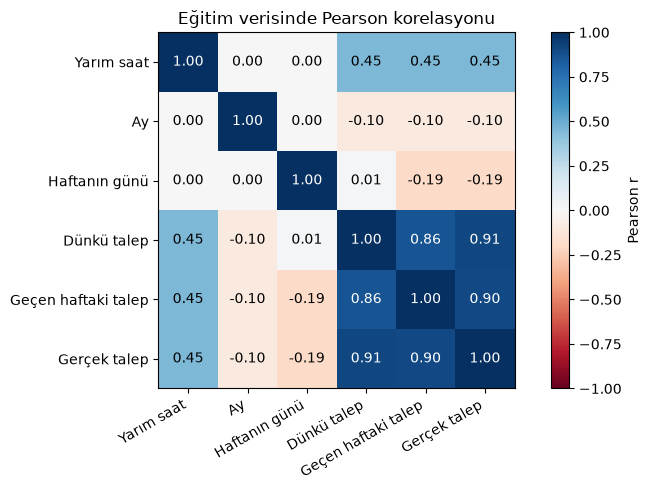

In [5]:
labels = ["Yarım saat", "Ay", "Haftanın günü", "Dünkü talep", "Geçen haftaki talep", "Gerçek talep"]
correlation = train[features + ["demand_mw"]].corr()

fig, ax = plt.subplots(figsize=(8, 5))
heatmap = ax.imshow(correlation, cmap="RdBu", vmin=-1, vmax=1)
positions = range(len(labels))
ax.set_xticks(positions, labels, rotation=30, ha="right")
ax.set_yticks(positions, labels)
ax.set_title("Eğitim verisinde Pearson korelasyonu")
for row, values in enumerate(correlation.to_numpy()):
    for col, value in enumerate(values):
        color = "white" if abs(value) >= 0.65 else "black"
        ax.text(col, row, f"{value:z.2f}", ha="center", va="center", color=color)
fig.colorbar(heatmap, ax=ax, label="Pearson r")
plt.tight_layout()
plt.show()

Dünkü aynı saatin talebi (r = 0,91) ve geçen haftaki aynı saatin talebi (r = 0,90) hedefle en güçlü doğrusal ilişkiyi gösterdi.

## Model karşılaştırması

MAE, tahminin gerçekleşen talepten ortalama kaç MW saptığını gösteriyor. Basit referans olarak dünkü ve geçen haftaki aynı dilimin talebini kullanıyoruz.

In [6]:
models = {
    "Ridge": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regressor", Ridge()),
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("regressor", RandomForestRegressor(
            n_estimators=80, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=4
        )),
    ]),
    "Histogram Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("regressor", HistGradientBoostingRegressor(
            max_iter=150, max_leaf_nodes=31, learning_rate=0.1, early_stopping=False, random_state=42
        )),
    ]),
}

cv_results = {
    name: -cross_val_score(model, X_train, y_train, cv=year_folds, scoring="neg_mean_absolute_error", error_score="raise").mean()
    for name, model in models.items()
}
best_model_name = min(cv_results, key=cv_results.get)
pd.Series(cv_results, name="Doğrulama MAE (MW)").sort_values().round(1)

Histogram Gradient Boosting    1275.9
Random Forest                  1318.8
Ridge                          1474.6
Name: Doğrulama MAE (MW), dtype: float64

## GridSearchCV ile parametre araması

In [7]:
param_grids = {
    "Ridge": {"regressor__alpha": [0.1, 1, 10, 100]},
    "Random Forest": {
        "regressor__max_depth": [10, 12, 16],
        "regressor__min_samples_leaf": [5, 12],
    },
    "Histogram Gradient Boosting": {
        "regressor__max_iter": [100, 150, 250],
        "regressor__max_leaf_nodes": [15, 31],
        "regressor__learning_rate": [0.05, 0.1],
    },
}
search = GridSearchCV(
    models[best_model_name], param_grids[best_model_name],
    cv=year_folds, scoring="neg_mean_absolute_error", n_jobs=1, error_score="raise",
)
search.fit(X_train, y_train)
best_model = search.best_estimator_

print(best_model_name)
print(search.best_params_)
print(f"İlk doğrulama MAE: {cv_results[best_model_name]:.1f} MW")
print(f"Arama sonrası doğrulama MAE: {-search.best_score_:.1f} MW")

Histogram Gradient Boosting
{'regressor__learning_rate': 0.05, 'regressor__max_iter': 250, 'regressor__max_leaf_nodes': 15}
İlk doğrulama MAE: 1275.9 MW
Arama sonrası doğrulama MAE: 1265.0 MW


## 2025 test sonuçları

In [8]:
def regression_scores(actual, predicted):
    return {
        "MAE (MW)": mean_absolute_error(actual, predicted),
        "RMSE (MW)": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted),
    }

default_model = models[best_model_name].fit(X_train, y_train)
default_pred = default_model.predict(X_test)
y_pred = best_model.predict(X_test)
train_pred = best_model.predict(X_train)

median = y_train.median()
yesterday = X_test["demand_1d"].fillna(X_test["demand_7d"]).fillna(median)
last_week = X_test["demand_7d"].fillna(X_test["demand_1d"]).fillna(median)
results = {
    "Dünün aynı saati": regression_scores(y_test, yesterday),
    "Geçen haftanın aynı saati": regression_scores(y_test, last_week),
    f"{best_model_name} (ilk)": regression_scores(y_test, default_pred),
    f"{best_model_name} (ayarlı)": regression_scores(y_test, y_pred),
}
print(f"Ayarlı model eğitim MAE: {mean_absolute_error(y_train, train_pred):.1f} MW")
pd.DataFrame(results).T.round({"MAE (MW)": 1, "RMSE (MW)": 1, "R²": 3})

Ayarlı model eğitim MAE: 1157.4 MW


,MAE (MW),RMSE (MW),R²
Dünün aynı saati,1848.8,2576.9,0.826
Geçen haftanın aynı saati,2177.5,2920.1,0.776
Histogram Gradient Boosting (ilk),1335.7,1842.3,0.911
Histogram Gradient Boosting (ayarlı),1331.5,1829.5,0.912


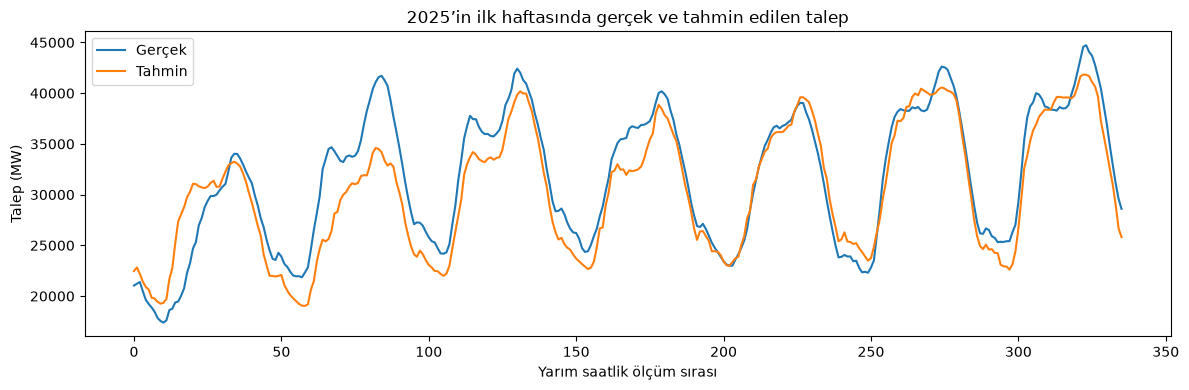

In [9]:
predictions = test[["date", "settlement_period", "demand_mw"]].copy()
predictions["prediction_mw"] = y_pred

first_week = predictions.head(7 * 48)
plt.figure(figsize=(12, 4))
plt.plot(first_week["demand_mw"].to_numpy(), label="Gerçek")
plt.plot(first_week["prediction_mw"].to_numpy(), label="Tahmin")
plt.title("2025’in ilk haftasında gerçek ve tahmin edilen talep")
plt.xlabel("Yarım saatlik ölçüm sırası")
plt.ylabel("Talep (MW)")
plt.legend()
plt.tight_layout()
plt.show()

Model ilk haftanın günlük yükseliş ve düşüşlerini büyük ölçüde izledi. Haftanın gerçek zirvesi 44.730 MW, tahmin serisinin zirvesi 41.824 MW idi. Haftalık MAE 2.245,2 MW oldu.

## Model tahmin eğrileri

Ocak ayında salı günü saat 18.00 için dünkü talebi değiştiriyoruz. Geçen haftaki talebi bu saat için eğitim medyanında tutuyoruz.

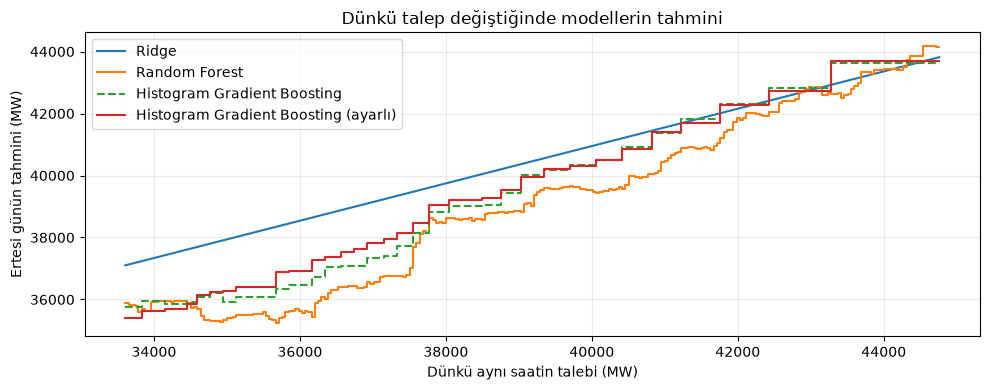

In [10]:
example = X_train[
    X_train["month"].eq(1) & X_train["weekday"].eq(1) & X_train["half_hour"].eq(36)
]
past_demand = np.linspace(example["demand_1d"].min(), example["demand_1d"].max(), 250)
profile = pd.DataFrame({
    "half_hour": 36,
    "month": 1,
    "weekday": 1,
    "demand_1d": past_demand,
    "demand_7d": example["demand_7d"].median(),
})
curve_models = {
    name: default_model if name == best_model_name else estimator.fit(X_train, y_train)
    for name, estimator in models.items()
}
curve_models[f"{best_model_name} (ayarlı)"] = best_model

fig, ax = plt.subplots(figsize=(10, 4))
for name, estimator in curve_models.items():
    ax.plot(
        past_demand, estimator.predict(profile[features]), label=name,
        linestyle="--" if name == best_model_name else "-",
        drawstyle="default" if isinstance(estimator.named_steps["regressor"], Ridge) else "steps-post",
    )
ax.set(
    title="Dünkü talep değiştiğinde modellerin tahmini",
    xlabel="Dünkü aynı saatin talebi (MW)",
    ylabel="Ertesi günün tahmini (MW)",
)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Ridge, dünkü talep değiştikçe sabit eğimle tepki verdi. Ağaç modelleri farklı talep aralıklarında farklı tepki gösterdi. Model sıralaması yıllık doğrulama MAE’sine dayanıyor.

## Yüksek talep uyarıları

Yüksek talep eşiğini eğitim verisinin 90. yüzdeliği olarak alıyoruz. 2025 testinde gerçekleşen talep ve model tahmini bu eşiğe göre değerlendirilir.

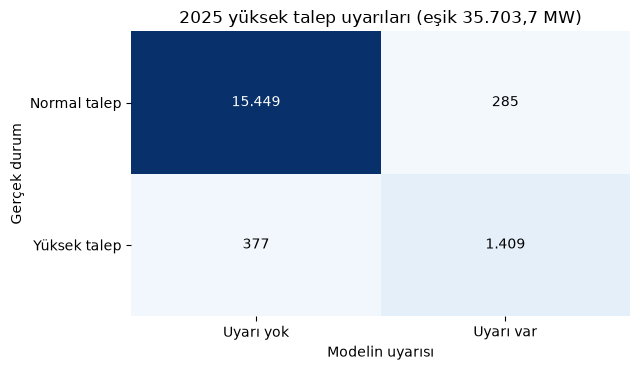

In [11]:
high_demand_threshold = y_train.quantile(0.90)
actual_high = y_test.ge(high_demand_threshold)
warning = pd.Series(y_pred, index=y_test.index).ge(high_demand_threshold)

counts = pd.crosstab(actual_high, warning).reindex(
    index=[False, True], columns=[False, True], fill_value=0
)
labels = counts.to_numpy()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.imshow(labels, cmap="Blues", vmin=0, aspect="auto")
ax.set_xticks([0, 1], ["Uyarı yok", "Uyarı var"])
ax.set_yticks([0, 1], ["Normal talep", "Yüksek talep"])
threshold_label = f"{high_demand_threshold:,.1f}".translate(str.maketrans(",.", ".,"))
ax.set(
    title=f"2025 yüksek talep uyarıları (eşik {threshold_label} MW)",
    xlabel="Modelin uyarısı", ylabel="Gerçek durum",
)
for row, values in enumerate(labels):
    for col, count in enumerate(values):
        color = "white" if count > labels.max() / 2 else "black"
        ax.text(col, row, f"{count:,}".replace(",", "."), ha="center", va="center", color=color)
for spine in ax.spines.values():
    spine.set_visible(False)
plt.tight_layout()
plt.show()

Model, yüksek talep görülen 1.786 dilimin 1.409’unu yakaladı. 377 yüksek talep dilimini kaçırdı ve 285 normal talep diliminde yanlış uyarı verdi.

## Değişken önemi

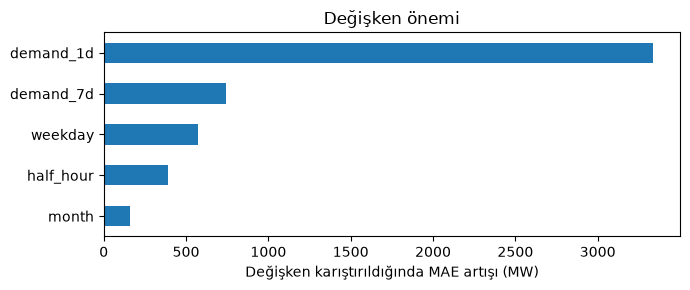

In [12]:
importance = permutation_importance(
    best_model, X_test, y_test, scoring="neg_mean_absolute_error", n_repeats=5, random_state=42
)
importance_mw = pd.Series(importance.importances_mean, index=features).sort_values()
importance_mw.plot.barh(figsize=(7, 3), title="Değişken önemi")
plt.xlabel("Değişken karıştırıldığında MAE artışı (MW)")
plt.tight_layout()
plt.show()

Dünkü aynı saatin talebi karıştırıldığında test MAE’si en fazla arttı (yaklaşık 3.333 MW). Geçen haftaki talep ikinci sıradaydı (yaklaşık 744 MW).

## SHAP ile model açıklaması

Histogram Gradient Boosting’in değişken katkılarını 2025 test döneminden sabit tohumla çekilen 1.000 yarım saatlik kayıtta inceledik. Açıklayıcıya, final modelin kullandığı medyan doldurma adımından geçmiş girdileri verdik.

In [13]:
import shap

shap_sample = X_test.sample(n=1000, random_state=42)
imputer = best_model.named_steps["imputer"]
regressor = best_model.named_steps["regressor"]
feature_labels = ["Yarım saat", "Ay", "Haftanın günü", "Dünkü talep", "Geçen haftaki talep"]

explainer = shap.TreeExplainer(regressor, feature_names=feature_labels)
shap_values = explainer(imputer.transform(shap_sample))

example_index = test.index[
    test["date"].eq(pd.Timestamp("2025-01-14")) & test["half_hour"].eq(36)
][0]
example_input = imputer.transform(X_test.loc[[example_index]])
example_shap = explainer(example_input)[0]
example_actual = y_test.loc[example_index]
example_prediction = best_model.predict(X_test.loc[[example_index]])[0]

c:\Users\ozgur\Desktop\infotech_projeler\Electricity_Demand_Prediction\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


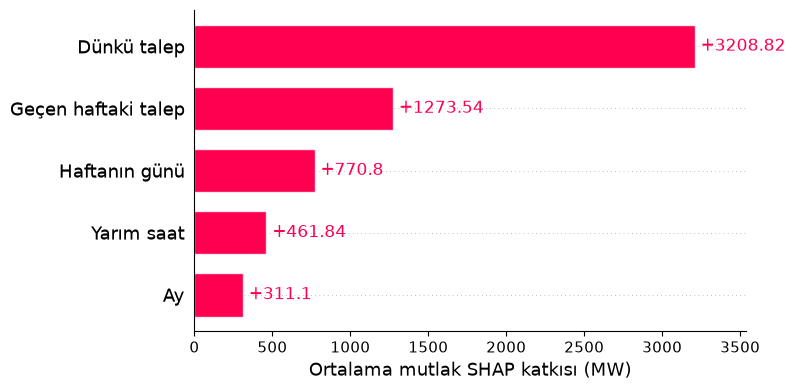

In [14]:
plt.figure()
shap.plots.bar(shap_values, show=False)
plt.gca().set_xlabel('Ortalama mutlak SHAP katkısı (MW)')
plt.tight_layout()
plt.show()

Çubuklar katkıların mutlak değerlerinin ortalamasını gösteriyor. Dünkü talep ve geçen haftaki talep ilk iki sırada.

Gerçek: 42134.00 | Tahmin: 42715.23


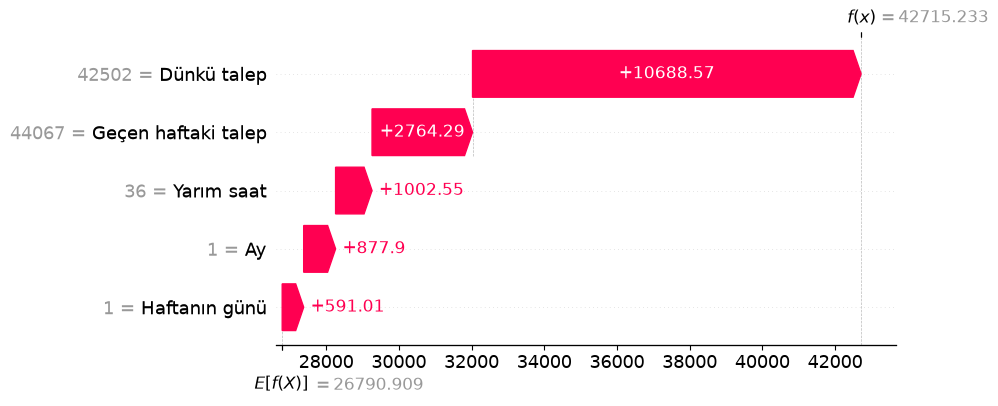

In [15]:
print(f"Gerçek: {example_actual:.2f} | Tahmin: {example_prediction:.2f}")
plt.figure()
shap.plots.waterfall(example_shap, show=False)
plt.show()

**14 Ocak 2025 saat 18.00 tahmini.** Tahmin, referans değere her girdinin katkısı eklenerek oluşturuldu. Bu kayıtta Dünkü talep tahmini yukarı çekti; Geçen haftaki talep tahmini yukarı çekti.

In [18]:
from pathlib import Path

import joblib

model_directory = Path("./models")
model_directory.mkdir(exist_ok=True)

test_scores = regression_scores(y_test, y_pred)

model_artifact = {
    "model": best_model,
    "model_name": best_model_name,
    "feature_columns": features,
    "test_mae": test_scores["MAE (MW)"],
    "test_rmse": test_scores["RMSE (MW)"],
    "test_r2": test_scores["R²"],
}

model_path = model_directory / "electricity_demand_model.joblib"
joblib.dump(model_artifact, model_path)

print(f"Model kaydedildi: {model_path}")

Model kaydedildi: models\electricity_demand_model.joblib
